# 02 · Experimento: centralizado vs. local vs. aprendizaje federado

**Hipótesis general:** el aprendizaje federado mejora significativamente la capacidad de detección de los IDS en redes IoT de borde.

| Esquema | Rol en el diseño |
|---|---|
| Local (aislado) | **Pre-test**: cada dispositivo entrena solo con su tráfico |
| FedAvg (no-IID) | **Post-test**: tratamiento principal |
| FedAvg (IID), FedProx μ | Variantes de la VI (heterogeneidad, agregación) |
| Centralizado | Cota superior de referencia (para la brecha ΔF1) |

Todos usan el mismo MLP y el mismo presupuesto de entrenamiento (R × E épocas). Se repite con 5 semillas.

In [1]:
import os, sys, platform
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json
import numpy as np, pandas as pd, sklearn, scipy
import matplotlib.pyplot as plt
from fl_ids.experiment import DEFAULT_CONFIG, run_experiment, run_sensitivity
from fl_ids.partition import split_train_test, assign_attacks, make_clients, label_distribution, js_divergence
from fl_ids.analysis import (summary, wilcoxon_tests, observation_register,
                             plot_convergence, plot_client_bars, plot_partition, plot_confusion,
                             sensitivity_table, plot_sensitivity)

DATA_FILE = ROOT / "data" / "processed" / "flows_labeled.parquet"
RES_DIR = ROOT / "results"; FIG_DIR = RES_DIR / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------- CONFIGURACIÓN (VI) -------------------------
CONFIG = {
    **DEFAULT_CONFIG,
    "clients": ["Temperature_and_Humidity", "Distance", "Water_Level", "phValue", "Soil_Moisture"],  # K = 5
    "label_level": "attack",    # "attack" (Normal + 14 ataques) o "category" (Normal + 5 categorías)
    "seeds": [0, 1, 2, 3, 4],
    "rounds": 30,               # R: rondas de comunicación
    "local_epochs": 2,          # E: épocas locales por ronda
    "mus": [0.01, 0.1],         # μ de FedProx
}
data = pd.read_parquet(DATA_FILE)
print(f"{len(data):,} flujos | clases: {data['label'].nunique()}")
print("Python", platform.python_version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

176,118 flujos | clases: 14
Python 3.13.16 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1


## 1 · Partición de los datos entre clientes
**no-IID:** cada dispositivo entrena con el tráfico normal de *su* sensor y solo con algunos tipos de ataque (reparto disjunto). **IID:** el mismo total barajado y repartido en partes iguales. La heterogeneidad se mide con la divergencia de Jensen-Shannon (JS) respecto a la distribución global.

{
 "Temperature_and_Humidity": [
  "Backdoor",
  "OS_Fingerprinting",
  "Uploading"
 ],
 "Distance": [
  "DDoS_HTTP_Flood",
  "Password",
  "Vulnerability_scanner"
 ],
 "Water_Level": [
  "DDoS_ICMP_Flood",
  "Port_Scanning",
  "XSS"
 ],
 "phValue": [
  "DDoS_TCP_SYN_Flood",
  "Ransomware"
 ],
 "Soil_Moisture": [
  "DDoS_UDP_Flood",
  "SQL_injection"
 ]
}


,JS no-IID,JS IID
Temperature_and_Humidity,0.231,0.0
Distance,0.167,0.0
Water_Level,0.229,0.0
phValue,0.225,0.0
Soil_Moisture,0.230,0.0
Promedio,0.216,0.0


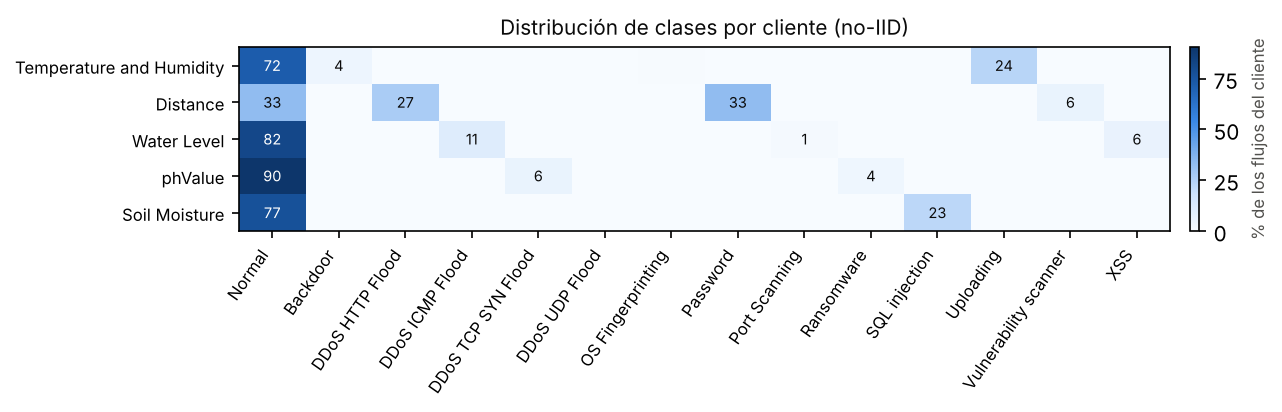

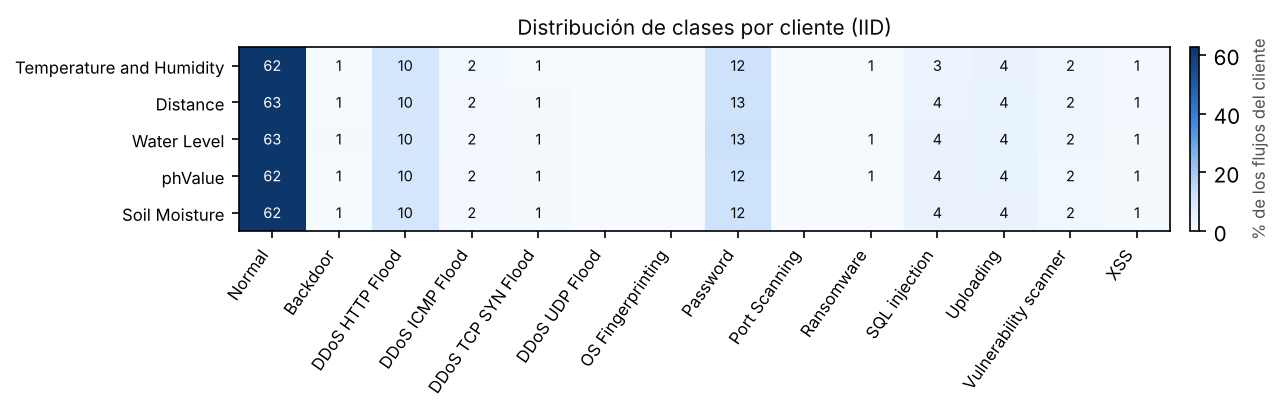

In [2]:
attacks = sorted(data.loc[data["label"] != "Normal", "label"].unique())
assignment = CONFIG["attack_assignment"] or assign_attacks(attacks, CONFIG["clients"])
classes = ["Normal"] + attacks
sub = data[(data["label"] != "Normal") | data["device"].isin(CONFIG["clients"])]
train0, test0 = split_train_test(sub, CONFIG["test_size"], seed=0)
dist = {m: label_distribution(make_clients(train0, test0, CONFIG["clients"], assignment, m), classes)
        for m in ["noniid", "iid"]}
js = pd.DataFrame({"JS no-IID": js_divergence(dist["noniid"]), "JS IID": js_divergence(dist["iid"])})
js.loc["Promedio"] = js.mean()
js.round(3).to_csv(RES_DIR / "tabla_heterogeneidad_JS.csv", encoding="utf-8-sig")
print(json.dumps(assignment, indent=1, ensure_ascii=False))
display(js.round(3))
plot_partition(dist["noniid"], "Distribución de clases por cliente (no-IID)", FIG_DIR / "fig1_particion_noiid.png"); plt.show()
plot_partition(dist["iid"], "Distribución de clases por cliente (IID)", FIG_DIR / "fig2_particion_iid.png"); plt.show()

## 2 · Ejecución del experimento
Tiempo aproximado en una laptop: 3–6 min por semilla. Al terminar, todo queda guardado en `results/`.

In [3]:
out = run_experiment(data, CONFIG)
res, hist, info = out["per_client"], out["history"], out["method_info"]
res.to_csv(RES_DIR / "resultados_por_cliente.csv", index=False, encoding="utf-8-sig")
hist.to_csv(RES_DIR / "historial_rondas.csv", index=False, encoding="utf-8-sig")
info.to_csv(RES_DIR / "comunicacion_y_tiempos.csv", index=False, encoding="utf-8-sig")
json.dump({"config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()},
           "asignacion_ataques": out["assignment"], "parametros_modelo": out["n_params"]},
          open(RES_DIR / "configuracion_experimento.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)
print("Parámetros del MLP:", out["n_params"])


=== Semilla 0 (68 s) ===
                            F1   F1nv   FPR
metodo                                     
Centralizado             84.39  83.24  0.01
Local                    12.18   0.16  0.02
FedAvg (IID)             84.39  83.23  0.07
FedAvg (no-IID)          34.61  29.57  0.05
FedProx μ=0.01 (no-IID)  48.54  44.48  0.04
FedProx μ=0.1 (no-IID)   47.16  42.99  0.07



=== Semilla 1 (71 s) ===
                            F1   F1nv   FPR
metodo                                     
Centralizado             83.35  82.10  0.01
Local                    12.21   0.00  0.01
FedAvg (IID)             83.45  82.22  0.01
FedAvg (no-IID)          24.36  18.53  0.02
FedProx μ=0.01 (no-IID)  47.64  43.51  0.01
FedProx μ=0.1 (no-IID)   49.64  45.66  0.00



=== Semilla 2 (71 s) ===
                            F1   F1nv   FPR
metodo                                     
Centralizado             83.60  82.38  0.01
Local                    11.69   0.00  0.01
FedAvg (IID)             82.57  81.28  0.00
FedAvg (no-IID)          28.72  23.33  0.01
FedProx μ=0.01 (no-IID)  55.26  51.72  0.01
FedProx μ=0.1 (no-IID)   50.04  46.15  0.03



=== Semilla 3 (79 s) ===
                            F1   F1nv   FPR
metodo                                     
Centralizado             83.04  81.78  0.02
Local                    12.71   0.00  0.02
FedAvg (IID)             81.12  79.73  0.04
FedAvg (no-IID)          36.38  31.33  0.06
FedProx μ=0.01 (no-IID)  57.61  54.27  0.02
FedProx μ=0.1 (no-IID)   54.88  51.28  0.05



=== Semilla 4 (68 s) ===
                            F1   F1nv   FPR
metodo                                     
Centralizado             83.37  82.13  0.03
Local                    11.85   0.00  0.01
FedAvg (IID)             83.02  81.76  0.02
FedAvg (no-IID)          27.99  22.46  0.03
FedProx μ=0.01 (no-IID)  53.81  50.30  0.03
FedProx μ=0.1 (no-IID)   54.69  51.16  0.02
Parámetros del MLP: 4590


## 3 · Resultados (media ± desviación estándar entre semillas)

In [4]:
tab = summary(res, info)
tab.to_csv(RES_DIR / "tabla_resultados.csv", encoding="utf-8-sig")
tab

,F1 macro (%),FPR (%),Brecha vs. central (pp),F1 ataques no vistos (%),Comunicación (MB),Tiempo local/ronda (s)
Esquema,,,,,,
Centralizado,83.55 ± 0.51,0.02 ± 0.01,0.00 ± 0.00,82.33 ± 0.56,11.90 ± 0.00,0.34 ± 0.01
Local,12.13 ± 0.39,0.01 ± 0.01,71.42 ± 0.73,0.03 ± 0.07,0.00 ± 0.00,0.07 ± 0.00
FedAvg (IID),82.91 ± 1.21,0.03 ± 0.03,0.64 ± 0.84,81.64 ± 1.29,5.51 ± 0.00,0.07 ± 0.00
FedAvg (no-IID),30.41 ± 4.96,0.04 ± 0.02,53.14 ± 4.89,25.05 ± 5.29,5.51 ± 0.00,0.07 ± 0.00
FedProx μ=0.01 (no-IID),52.57 ± 4.32,0.02 ± 0.01,30.98 ± 4.63,48.85 ± 4.67,5.51 ± 0.00,0.08 ± 0.02
FedProx μ=0.1 (no-IID),51.28 ± 3.38,0.03 ± 0.03,32.27 ± 3.81,47.45 ± 3.65,5.51 ± 0.00,0.07 ± 0.00


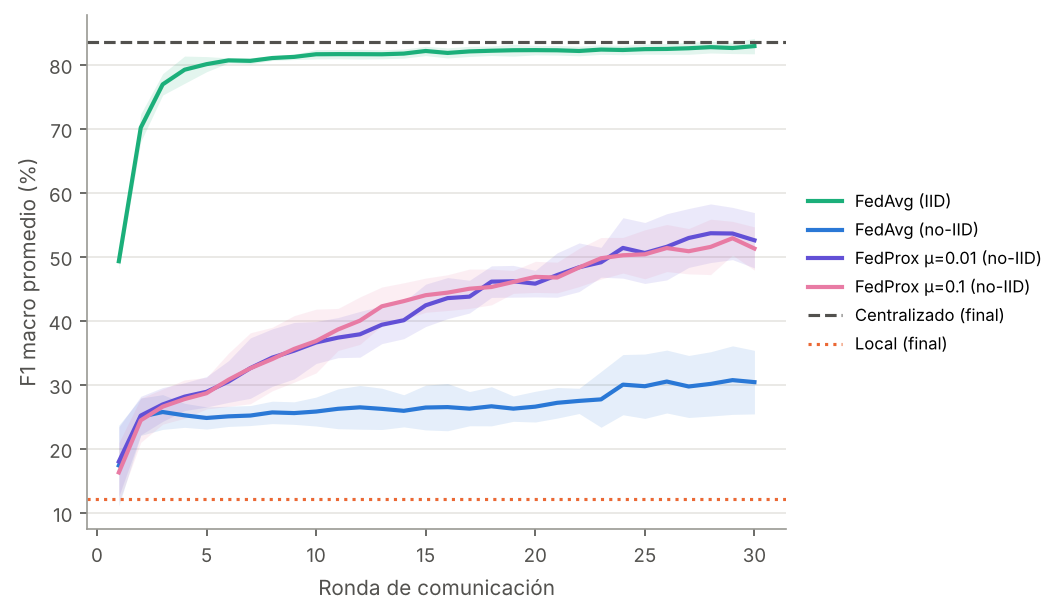

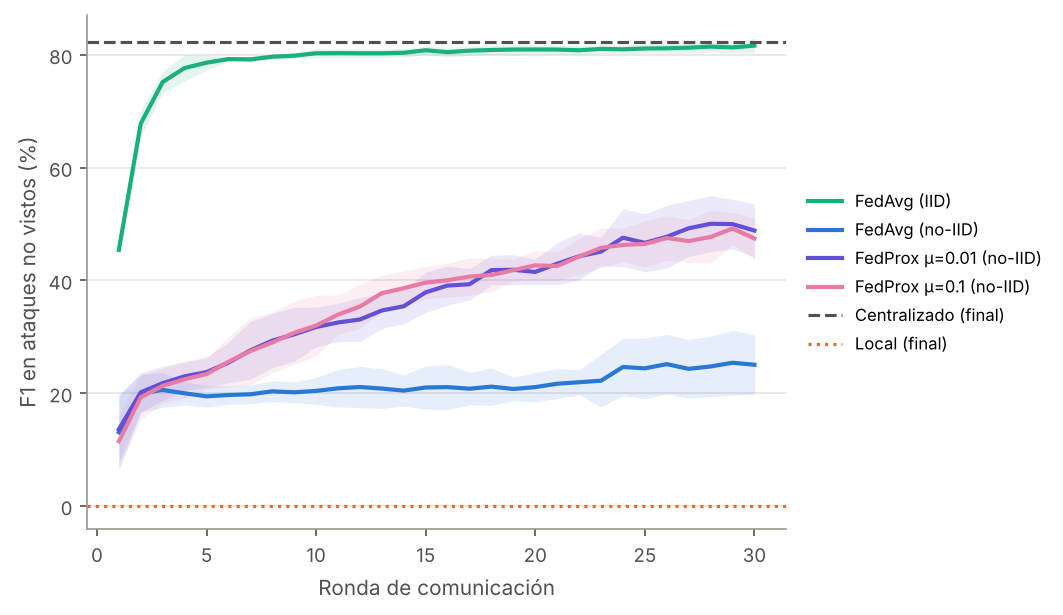

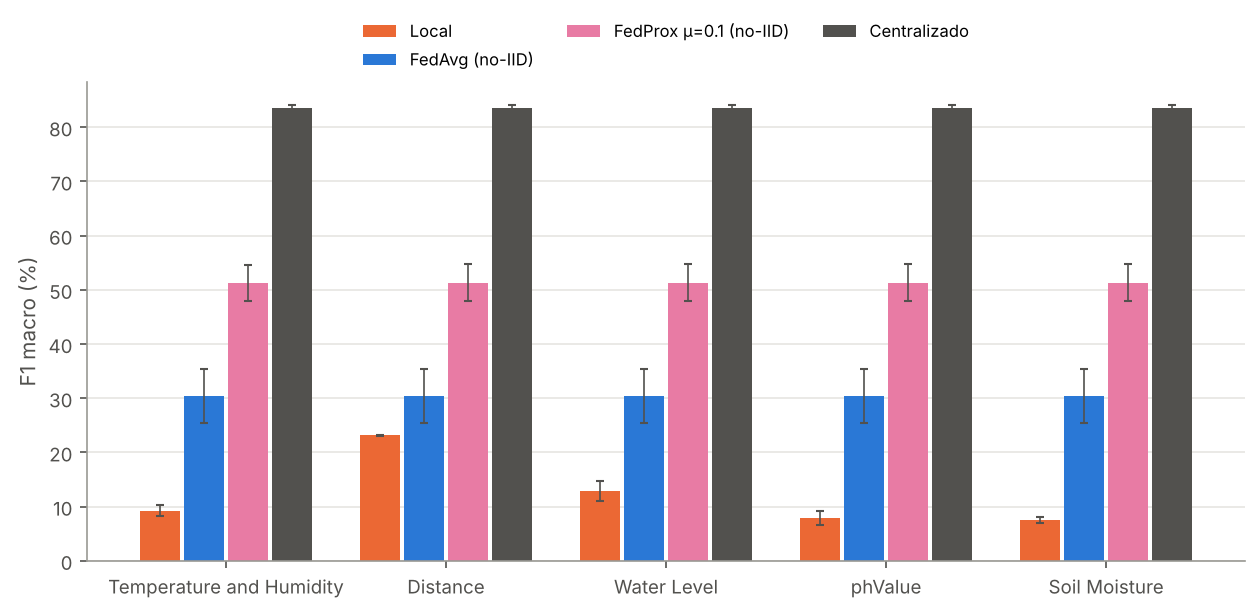

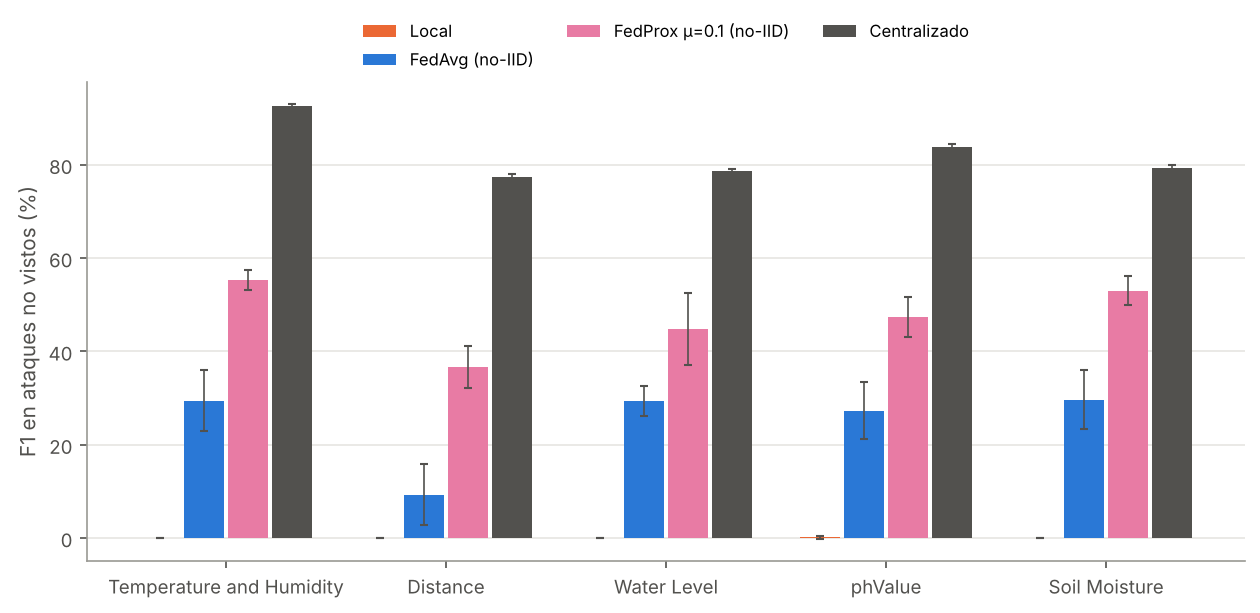

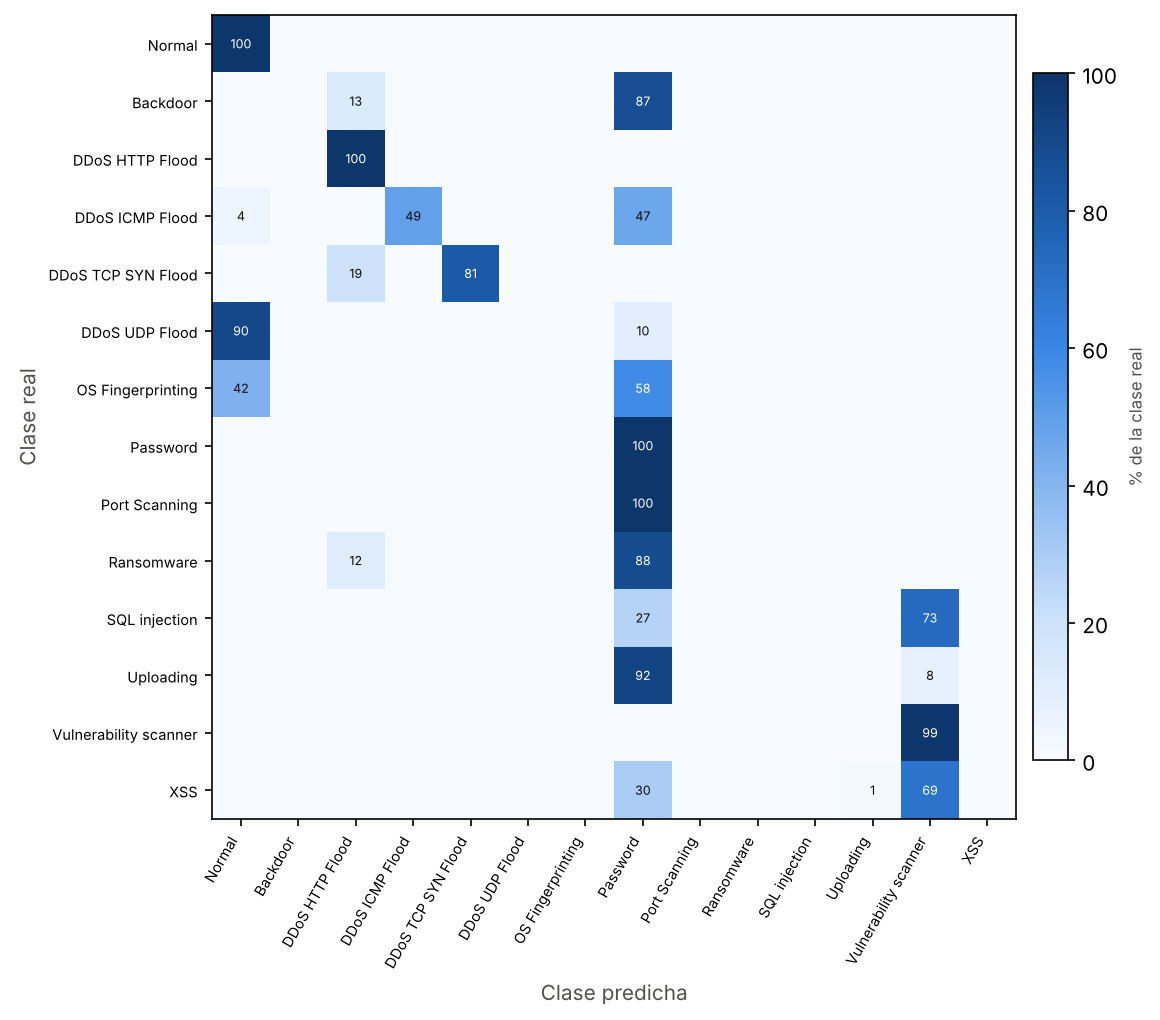

In [5]:
plot_convergence(hist, res, "F1", FIG_DIR / "fig3_convergencia_f1.png"); plt.show()
plot_convergence(hist, res, "F1nv", FIG_DIR / "fig4_convergencia_f1_no_vistos.png"); plt.show()
main = ["Local", "FedAvg (no-IID)", [m for m in res["metodo"].unique() if m.startswith("FedProx")][-1], "Centralizado"]
plot_client_bars(res, "F1", main, FIG_DIR / "fig5_f1_por_cliente.png"); plt.show()
plot_client_bars(res, "F1nv", main, FIG_DIR / "fig6_f1_no_vistos_por_cliente.png"); plt.show()
plot_confusion(out["confusion"], out["classes"], FIG_DIR / "fig7_confusion_fedavg_noiid.png"); plt.show()

## 4 · Contraste de hipótesis
Prueba de rangos con signo de Wilcoxon, pareada por (semilla, cliente), α = 0,05.
* **H.E.1 (desempeño predictivo):** Local → FedAvg (no-IID) en F1 y FPR.
* **H.E.2 (generalización):** Local → FedAvg (no-IID) en F1 de ataques no vistos y en la brecha ΔF1.
* **H.E.3 (eficiencia):** volumen de comunicación del aprendizaje federado frente al envío centralizado de los datos (determinista, se reporta la reducción porcentual).

In [6]:
tests = wilcoxon_tests(res)
tests.to_csv(RES_DIR / "pruebas_wilcoxon.csv", index=False, encoding="utf-8-sig")
display(tests)
c = info.groupby("metodo")[["comm_MB", "comm_raw_MB"]].mean()
fl = c.loc["FedAvg (no-IID)", "comm_MB"]
print(f"H.E.3 · Federado: {fl:.2f} MB | Centralizado (registros de flujo): {c.loc['Centralizado','comm_MB']:.2f} MB "
      f"| Centralizado (bytes de tráfico): {c.loc['Centralizado','comm_raw_MB']:.2f} MB")
print(f"Reducción vs. registros de flujo: {100*(1 - fl/c.loc['Centralizado','comm_MB']):.1f} % | "
      f"vs. tráfico: {100*(1 - fl/c.loc['Centralizado','comm_raw_MB']):.1f} %")

,comparación,métrica,n pares,media A,media B,mediana Δ (B−A),W,p-valor,significativo (α=0.05)
0,Local → FedAvg (no-IID),F1,25,12.13,30.41,20.00,0.0,5.960464e-08,Sí
1,Local → FedAvg (no-IID),F1nv,25,0.03,25.05,26.60,0.0,1.227919e-05,Sí
2,Local → FedAvg (no-IID),FPR,25,0.01,0.04,0.00,10.5,7.593330e-02,No
3,Local → FedAvg (no-IID),dF1,25,71.42,53.14,-20.00,0.0,5.960464e-08,Sí
4,FedAvg (IID) → FedAvg (no-IID),F1,25,82.91,30.41,-53.85,0.0,1.201433e-05,Sí
5,FedAvg (no-IID) → FedProx μ=0.01 (no-IID),F1,25,30.41,52.57,23.28,0.0,1.199247e-05,Sí
6,FedAvg (no-IID) → FedProx μ=0.1 (no-IID),F1,25,30.41,51.28,21.32,0.0,1.211310e-05,Sí
7,FedAvg (no-IID) → FedProx μ=0.01 (no-IID),F1nv,25,25.05,48.85,24.81,0.0,5.960464e-08,Sí
8,FedAvg (no-IID) → FedProx μ=0.1 (no-IID),F1nv,25,25.05,47.45,22.93,0.0,5.960464e-08,Sí


H.E.3 · Federado: 5.51 MB | Centralizado (registros de flujo): 11.90 MB | Centralizado (bytes de tráfico): 255.76 MB
Reducción vs. registros de flujo: 53.7 % | vs. tráfico: 97.8 %


## 5 · Registro de observación estructurada (pre-test vs. post-test)
Llena automáticamente la matriz del instrumento: **Pre-test = Local**, **Post-test = FedAvg (no-IID)**. El volumen de comunicación del pre-test corresponde al envío centralizado de los registros de flujo (el entrenamiento aislado no comunica datos).

In [7]:
reg = observation_register(res, info, pre="Local", post="FedAvg (no-IID)")
reg.to_csv(RES_DIR / "registro_observacion.csv", index=False, encoding="utf-8-sig")
reg

,Bloque,Indicador,Pre-test,Post-test,Diferencia (Δ),Variación relativa (%),Nivel post-test
0,CLIENTE 1: Temperature_and_Humidity,Desempeño: F1-score macro (%),9.21,30.40,21.19,230.0,Bajo (Insuficiente)
1,CLIENTE 1: Temperature_and_Humidity,Desempeño: Tasa de falsos positivos (%),0.02,0.15,0.13,N/A,Óptimo
2,CLIENTE 1: Temperature_and_Humidity,Generalización: Brecha frente al modelo centra...,74.32,53.13,-21.19,-28.5,Deficiente
3,CLIENTE 1: Temperature_and_Humidity,Generalización: F1 en ataques no vistos localm...,0.00,29.48,29.48,N/A,Bajo
4,CLIENTE 2: Distance,Desempeño: F1-score macro (%),23.16,30.41,7.25,31.3,Bajo (Insuficiente)
5,CLIENTE 2: Distance,Desempeño: Tasa de falsos positivos (%),0.02,0.01,-0.01,N/A,Óptimo
6,CLIENTE 2: Distance,Generalización: Brecha frente al modelo centra...,60.39,53.14,-7.25,-12.0,Deficiente
7,CLIENTE 2: Distance,Generalización: F1 en ataques no vistos localm...,0.00,9.32,9.32,N/A,Bajo
8,CLIENTE 3: Water_Level,Desempeño: F1-score macro (%),12.81,30.42,17.60,137.3,Bajo (Insuficiente)
9,CLIENTE 3: Water_Level,Desempeño: Tasa de falsos positivos (%),0.01,0.01,0.00,N/A,Óptimo


## 6 · Análisis de sensibilidad: configuración del entrenamiento federado
Dimensión 3 de la VI. En el escenario no-IID se varían las **épocas locales** E ∈ {1, 2, 5} y se registran hasta **R = 100 rondas** (el historial por ronda equivale a haber fijado R = r), para FedAvg y FedProx μ = 0,01, con 3 semillas. Responde si la brecha del escenario no-IID se debe a falta de entrenamiento o a la heterogeneidad de los datos. Tiempo aproximado: 20–40 min.

semilla 0 | FedAvg | E=1: F1 final 47.4 % (24 s)


semilla 0 | FedProx μ=0.01 | E=1: F1 final 62.4 % (24 s)


semilla 0 | FedAvg | E=2: F1 final 36.5 % (40 s)


semilla 0 | FedProx μ=0.01 | E=2: F1 final 54.7 % (41 s)


semilla 0 | FedAvg | E=5: F1 final 54.2 % (94 s)


...

semilla 2 | FedProx μ=0.01 | E=2: F1 final 64.1 % (39 s)


semilla 2 | FedAvg | E=5: F1 final 38.8 % (88 s)


semilla 2 | FedProx μ=0.01 | E=5: F1 final 60.5 % (87 s)


R = 10        R = 30         R = 60       R = 100
metodo         E                                                         
FedAvg         1  28.65 ± 6.23  33.14 ± 7.48  36.59 ± 13.09  43.59 ± 9.36
               2  25.75 ± 3.14  29.23 ± 5.14   32.50 ± 2.99  38.55 ± 7.42
               5  24.97 ± 2.84  26.13 ± 1.44   36.72 ± 3.33  45.37 ± 7.95
FedProx μ=0.01 1  38.60 ± 3.19  49.73 ± 2.63   58.36 ± 5.45  60.01 ± 7.56
               2  38.47 ± 1.53  50.48 ± 4.16   57.55 ± 5.83  57.42 ± 5.79
               5  38.18 ± 2.82  50.70 ± 3.54   59.46 ± 3.77  63.09 ± 2.91

R = 10        R = 30         R = 60        R = 100
metodo         E                                                          
FedAvg         1  23.54 ± 6.69  28.00 ± 8.08  31.67 ± 14.12  39.16 ± 10.12
               2  20.39 ± 3.32  23.81 ± 5.54   27.16 ± 3.19   33.78 ± 7.95
               5  19.47 ± 2.99  20.47 ± 1.47   31.77 ± 3.53   41.13 ± 8.55
FedProx μ=0.01 1  33.98 ± 3.54  45.81 ± 2.75   55.10 ± 5.89   56.84 ± 8.11
               2  33.75 ± 1.51  46.57 ± 4.49   54.26 ± 6.27   54.10 ± 6.23
               5  33.47 ± 2.97  46.81 ± 3.81   56.29 ± 4.09   60.24 ± 3.13

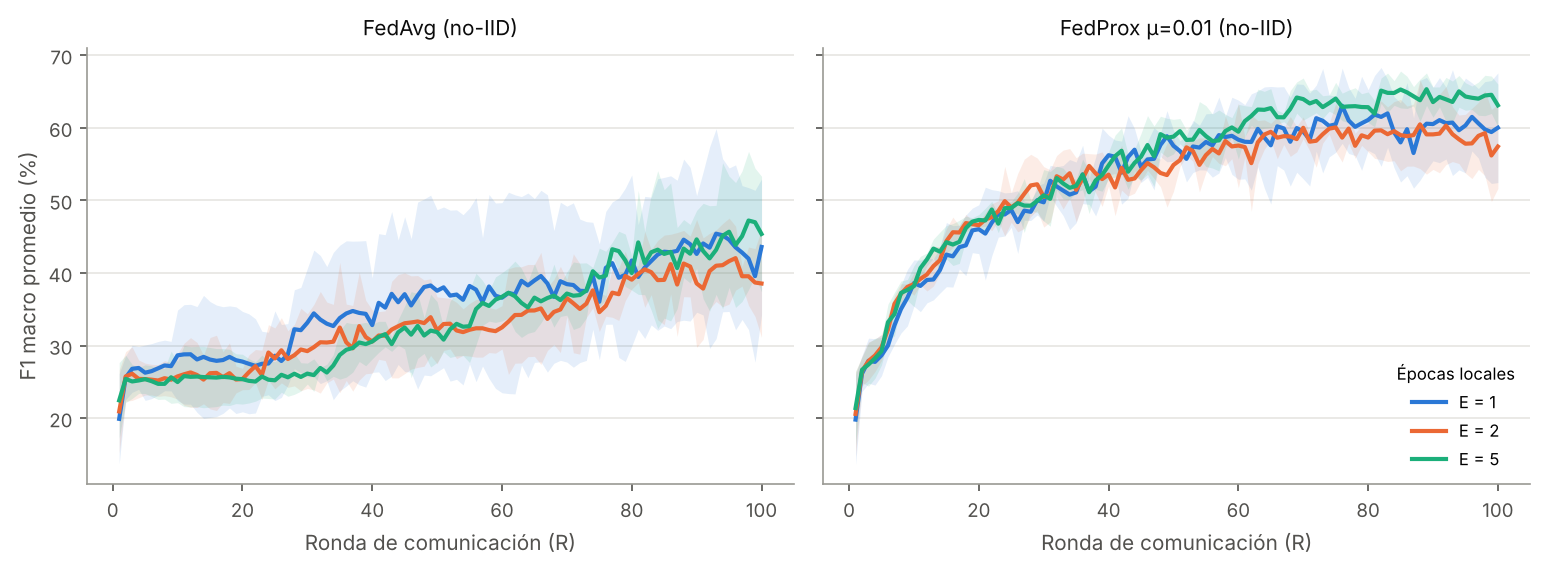

In [8]:
sens = run_sensitivity(data, CONFIG, local_epochs=(1, 2, 5), mus=(0.0, 0.01), max_rounds=100, seeds=(0, 1, 2))
sens.to_csv(RES_DIR / "sensibilidad_rondas_epocas.csv", index=False, encoding="utf-8-sig")
st = sensitivity_table(sens)
st.to_csv(RES_DIR / "tabla_sensibilidad.csv", encoding="utf-8-sig")
display(st)
display(sensitivity_table(sens, metric="F1nv"))
plot_sensitivity(sens, "F1", FIG_DIR / "fig8_sensibilidad_rondas_epocas.png"); plt.show()